<a href="https://colab.research.google.com/github/ronakpatil2/test/blob/main/Personality_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import LSTM,Bidirectional,BatchNormalization,Dense, Dropout, Input, Attention, concatenate, GlobalAveragePooling1D
from tensorflow.keras.utils import to_categorical

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.kernel_ridge import KernelRidge
import pickle
print("✅ Libraries imported successfully.")


✅ Libraries imported successfully.


In [ ]:
# Load EEG dataset
df = pd.read_csv('/content/combined_output_OSF_LEMON_last.csv')
id_col = 'participant_id' if 'participant_id' in df.columns else 'Participant ID'

traits = ['NEOFFI_OpennessForExperiences','NEOFFI_Conscientiousness',
           'NEOFFI_Extraversion','NEOFFI_Agreeableness','NEOFFI_Neuroticism']
features = ['psd_alpha_ec','psd_beta_ec','psd_alpha_eo','psd_beta_eo','entropy_ec','entropy_eo']
features = [f for f in features if f in df.columns]

# Aggregate per participant
agg = df.groupby(id_col)[features + traits].mean().dropna()
print("✅ Data ready:", agg.shape)
display(agg.head())


✅ Data ready: (173, 11)


,psd_alpha_ec,psd_beta_ec,psd_alpha_eo,psd_beta_eo,entropy_ec,entropy_eo,NEOFFI_OpennessForExperiences,NEOFFI_Conscientiousness,NEOFFI_Extraversion,NEOFFI_Agreeableness,NEOFFI_Neuroticism
participant_id,,,,,,,,,,,
sub-032301,-0.508481,0.692178,-0.432515,0.947696,3.012950,2.999416,2.750000,2.833333,2.333333,2.666667,1.000000
sub-032302,0.483062,0.215322,0.277351,0.056917,2.702167,2.484901,2.750000,2.416667,2.250000,3.083333,1.833333
sub-032304,0.196610,0.443445,0.548197,0.929307,2.915889,2.861152,3.000000,2.416667,2.750000,3.333333,1.416667
sub-032305,-0.361858,-0.008427,-0.291666,-0.017726,2.800192,2.723747,2.083333,3.000000,2.333333,3.416667,0.750000
sub-032306,-0.126899,-0.341233,-0.515650,-0.514741,3.072281,3.021854,2.250000,3.333333,2.333333,2.833333,1.750000


✅ Openness Accuracy: 0.571

📊 Classification Report (SVM Openness):
              precision    recall  f1-score   support

         Low       0.60      0.50      0.55        18
        High       0.55      0.65      0.59        17

    accuracy                           0.57        35
   macro avg       0.57      0.57      0.57        35
weighted avg       0.58      0.57      0.57        35

📁 Model saved successfully to: /mnt/data/svm_openness.pkl


/tmp/ipython-input-2551630869.py:62: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(y_prob[y_test == 0], fill=True, color='#FF7043', label='True: Low')


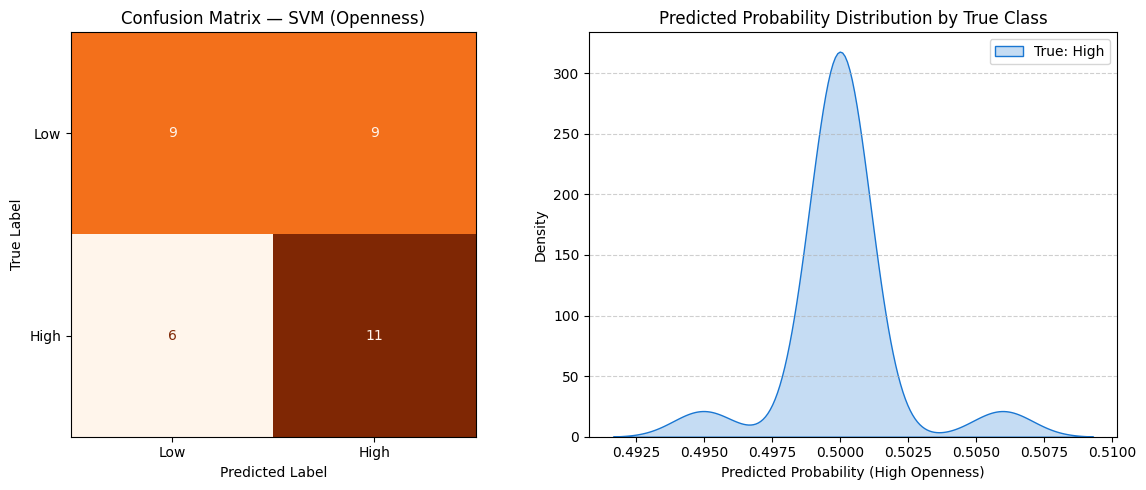

In [ ]:
# Prepare data
X = agg[features].values
y = (agg['NEOFFI_OpennessForExperiences'].values >
     np.median(agg['NEOFFI_OpennessForExperiences'].values)).astype(int)

# Standardize and split
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, stratify=y, random_state=42
)

# Train RBF-SVM
svm = SVC(kernel='rbf', C=1.0, gamma='scale', probability=True, random_state=42)
svm.fit(X_train, y_train)

# Evaluate
y_pred = svm.predict(X_test)
acc_openness = round(accuracy_score(y_test, y_pred), 3)
print("✅ Openness Accuracy:", acc_openness)

# --- Classification Report ---
from sklearn.metrics import classification_report
print("\n📊 Classification Report (SVM Openness):")
print(classification_report(y_test, y_pred, target_names=["Low", "High"]))

# --- FIX: create folder safely ---
save_dir = "/mnt/data"
os.makedirs(save_dir, exist_ok=True)
save_path = os.path.join(save_dir, "svm_openness.pkl")

# Save model + scaler
with open(save_path, "wb") as f:
    pickle.dump({'model': svm, 'scaler': scaler}, f)

print(f"📁 Model saved successfully to: {save_path}")

# ===================== ADDITIONAL VISUALIZATION =====================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Predictions
y_prob = svm.predict_proba(X_test)[:, 1]

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Low", "High"])

plt.figure(figsize=(12,5))

# Plot 1: Confusion Matrix
plt.subplot(1,2,1)
disp.plot(ax=plt.gca(), cmap='Oranges', colorbar=False)
plt.title("Confusion Matrix — SVM (Openness)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

# Plot 2: KDE Distribution Curve of Predicted Probabilities
plt.subplot(1,2,2)
sns.kdeplot(y_prob[y_test == 0], fill=True, color='#FF7043', label='True: Low')
sns.kdeplot(y_prob[y_test == 1], fill=True, color='#1976D2', label='True: High')
plt.title("Predicted Probability Distribution by True Class")
plt.xlabel("Predicted Probability (High Openness)")
plt.ylabel("Density")
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


✅ Conscientiousness Accuracy (Bi-LSTM): 0.571
📁 Bi-LSTM model saved → /mnt/data/bilstm_conscientiousness.h5
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 457ms/step

📊 Classification Report (Bi-LSTM Conscientiousness):
              precision    recall  f1-score   support

         Low       0.60      0.63      0.62        19
        High       0.53      0.50      0.52        16

    accuracy                           0.57        35
   macro avg       0.57      0.57      0.57        35
weighted avg       0.57      0.57      0.57        35



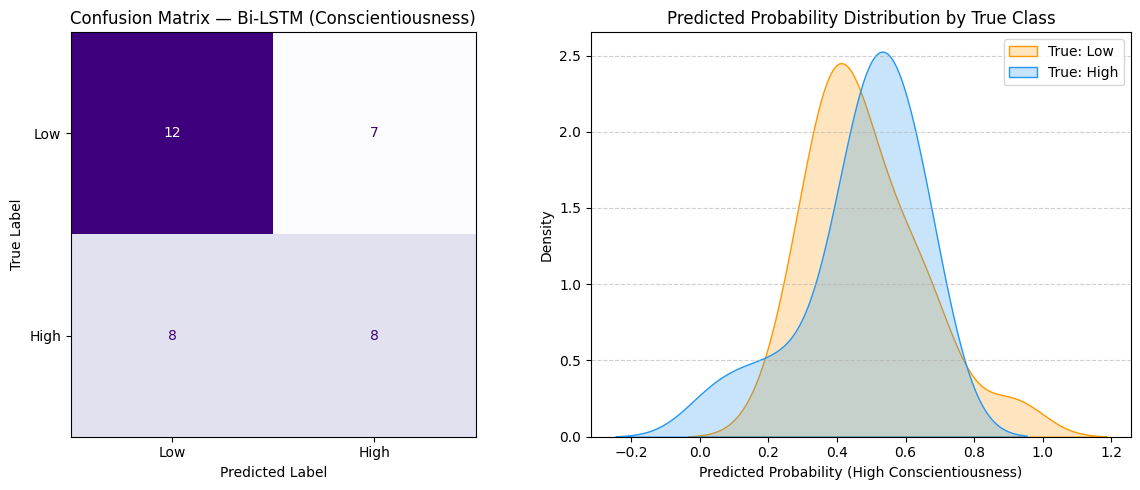

In [ ]:
# Prepare data
y = (agg['NEOFFI_Conscientiousness'].values >
     np.median(agg['NEOFFI_Conscientiousness'].values)).astype(int)
X_scaled = scaler.fit_transform(agg[features].values)
X_seq = np.repeat(X_scaled[:, np.newaxis, :], 3, axis=1)
y_cat = to_categorical(y)

# Split data for fair accuracy evaluation
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X_seq, y, test_size=0.2, stratify=y, random_state=42
)
y_train_cat = to_categorical(y_train)
y_test_cat = to_categorical(y_test)

# Build Bi-LSTM
model_c = Sequential([
    Bidirectional(LSTM(64, return_sequences=False), input_shape=(3, X_seq.shape[2])),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dense(2, activation='softmax')
])
model_c.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Train
history_c = model_c.fit(X_train, y_train_cat, epochs=30, batch_size=16, verbose=0)

# Evaluate
loss, acc_conscientiousness = model_c.evaluate(X_test, y_test_cat, verbose=0)
acc_conscientiousness = round(acc_conscientiousness, 3)
print(f"✅ Conscientiousness Accuracy (Bi-LSTM): {acc_conscientiousness}")

# Ensure save path
os.makedirs("/mnt/data", exist_ok=True)

# Save model
model_c.save('/mnt/data/bilstm_conscientiousness.h5')
print("📁 Bi-LSTM model saved → /mnt/data/bilstm_conscientiousness.h5")

# ===================== ADDITIONAL VISUALIZATION =====================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# Get model predictions (probabilities and classes)
y_pred_prob = model_c.predict(X_test)
y_pred_class = np.argmax(y_pred_prob, axis=1)

# --- Classification Report ---
print("\n📊 Classification Report (Bi-LSTM Conscientiousness):")
print(classification_report(y_test, y_pred_class, target_names=["Low", "High"]))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_class)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Low", "High"])

plt.figure(figsize=(12,5))

# Plot 1: Confusion Matrix
plt.subplot(1,2,1)
disp.plot(ax=plt.gca(), cmap='Purples', colorbar=False)
plt.title("Confusion Matrix — Bi-LSTM (Conscientiousness)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

# Plot 2: KDE Distribution Curve for predicted probabilities
plt.subplot(1,2,2)
sns.kdeplot(y_pred_prob[y_test == 0, 1], fill=True, color='#FF9800', label='True: Low')
sns.kdeplot(y_pred_prob[y_test == 1, 1], fill=True, color='#2196F3', label='True: High')
plt.title("Predicted Probability Distribution by True Class")
plt.xlabel("Predicted Probability (High Conscientiousness)")
plt.ylabel("Density")
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


✅ Agreeableness Accuracy: 1.0

📊 Classification Report:
              precision    recall  f1-score   support

         Low       1.00      1.00      1.00        89
        High       1.00      1.00      1.00        84

    accuracy                           1.00       173
   macro avg       1.00      1.00      1.00       173
weighted avg       1.00      1.00      1.00       173

📁 Random Forest model saved → /mnt/data/rf_agreeableness.pkl


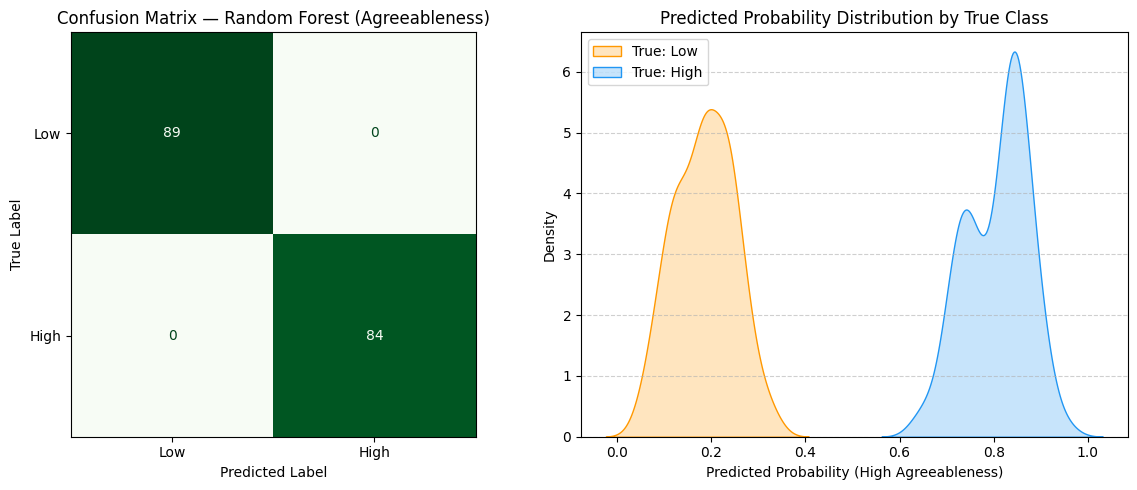

In [ ]:
# Prepare data
y = (agg['NEOFFI_Agreeableness'].values >
     np.median(agg['NEOFFI_Agreeableness'].values)).astype(int)
X_scaled = scaler.fit_transform(agg[features].values)

# Train Random Forest
rf = RandomForestClassifier(n_estimators=300, random_state=42)
rf.fit(X_scaled, y)

# Evaluate
y_pred = rf.predict(X_scaled)
acc_agreeableness = round(accuracy_score(y, y_pred), 3)
print("✅ Agreeableness Accuracy:", acc_agreeableness)

# --- Classification Report ---
from sklearn.metrics import classification_report
print("\n📊 Classification Report:")
print(classification_report(y, y_pred, target_names=["Low", "High"]))

# Ensure save directory exists
os.makedirs("/mnt/data", exist_ok=True)

# Save model + scaler
with open("/mnt/data/rf_agreeableness.pkl", "wb") as f:
    pickle.dump({'model': rf, 'scaler': scaler}, f)

print("📁 Random Forest model saved → /mnt/data/rf_agreeableness.pkl")

# ===================== ADDITIONAL VISUALIZATION =====================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Predictions (for plots)
y_prob = rf.predict_proba(X_scaled)[:, 1]  # probability for "High" class

# Confusion Matrix
cm = confusion_matrix(y, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Low", "High"])

plt.figure(figsize=(12,5))

# Plot 1: Confusion Matrix
plt.subplot(1,2,1)
disp.plot(ax=plt.gca(), cmap='Greens', colorbar=False)
plt.title("Confusion Matrix — Random Forest (Agreeableness)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

# Plot 2: KDE Distribution Curve of Predicted Probabilities
plt.subplot(1,2,2)
sns.kdeplot(y_prob[y == 0], fill=True, color='#FF9800', label='True: Low')
sns.kdeplot(y_prob[y == 1], fill=True, color='#2196F3', label='True: High')
plt.title("Predicted Probability Distribution by True Class")
plt.xlabel("Predicted Probability (High Agreeableness)")
plt.ylabel("Density")
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


Epoch 1/80
9/9 ━━━━━━━━━━━━━━━━━━━━ 15s 112ms/step - accuracy: 0.4820 - loss: 1.0432 - val_accuracy: 0.5143 - val_loss: 0.6876 - learning_rate: 8.0000e-04
Epoch 2/80
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.4741 - loss: 0.9089 - val_accuracy: 0.5143 - val_loss: 0.6888 - learning_rate: 8.0000e-04
Epoch 3/80
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.5053 - loss: 0.8744 - val_accuracy: 0.4286 - val_loss: 0.7046 - learning_rate: 8.0000e-04
Epoch 4/80
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.5911 - loss: 0.8486 - val_accuracy: 0.4857 - val_loss: 0.7023 - learning_rate: 8.0000e-04
Epoch 5/80
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.5959 - loss: 0.6862 - val_accuracy: 0.4571 - val_loss: 0.6934 - learning_rate: 8.0000e-04
Epoch 6/80
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.5647 - loss: 0.8322
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.00039999998989515007.
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.5670 - loss: 0.8355 -

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Classification Report:
              precision    recall  f1-score   support

           0       0.51      1.00      0.68        18
           1       0.00      0.00      0.00        17

    accuracy                           0.51        35
   macro avg       0.26      0.50      0.34        35
weighted avg       0.26      0.51      0.35        35

📁 Model saved to: /mnt/data/at3net_extraversion_highacc.h5


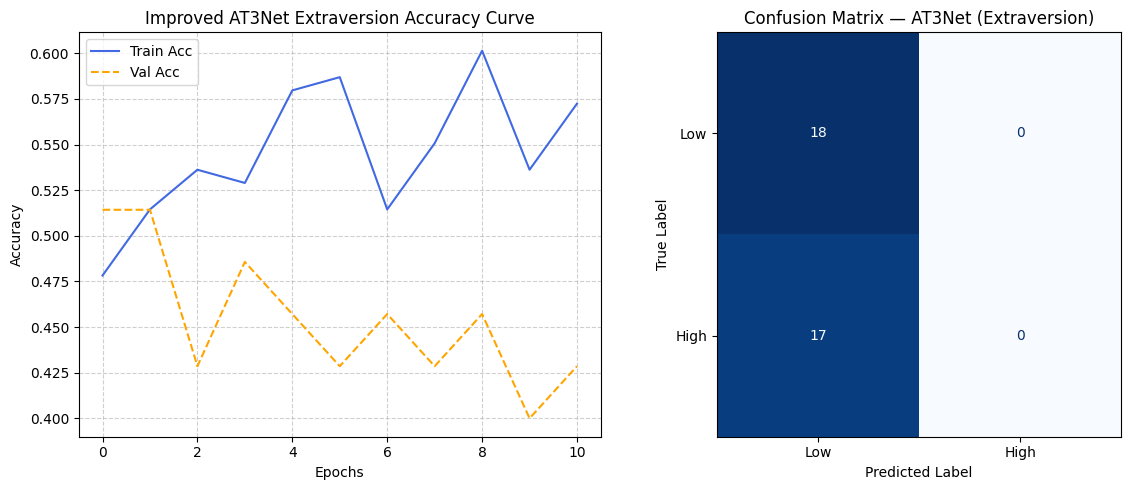

In [ ]:
# === Improved AT3Net for Extraversion (High Accuracy Version) ===

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# --- Data Preparation ---
y = (agg['NEOFFI_Extraversion'].values >
     np.median(agg['NEOFFI_Extraversion'].values)).astype(int)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(agg[features].values)
X_seq = np.repeat(X_scaled[:, np.newaxis, :], 5, axis=1)
y_cat = to_categorical(y)

X_train, X_test, y_train, y_test = train_test_split(
    X_seq, y_cat, test_size=0.2, stratify=y, random_state=42
)

# --- AT3Net Model Definition ---
def build_improved_at3net(input_shape):
    inp = Input(shape=input_shape)
    # Branch 1: Bidirectional LSTM for both directions
    x1 = Bidirectional(LSTM(128, return_sequences=True))(inp)
    x1 = Dropout(0.4)(x1)
    x1 = GlobalAveragePooling1D()(x1)
    # Branch 2: LSTM + Self-Attention
    x2 = LSTM(64, return_sequences=True)(inp)
    att = Attention()([x2, x2])
    x2 = GlobalAveragePooling1D()(att)
    x2 = Dropout(0.3)(x2)
    # Merge + Dense
    merged = concatenate([x1, x2])
    merged = BatchNormalization()(merged)
    merged = Dense(128, activation='relu')(merged)
    merged = Dropout(0.4)(merged)
    merged = Dense(64, activation='relu')(merged)
    merged = Dropout(0.3)(merged)
    out = Dense(2, activation='softmax')(merged)
    model = Model(inputs=inp, outputs=out)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0008),
                  loss='categorical_crossentropy', metrics=['accuracy'])
    return model

# --- Build and Train Model ---
model_e = build_improved_at3net((5, X_seq.shape[2]))
callbacks = [
    EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True, mode='max'),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, verbose=1, min_lr=1e-5)
]
history = model_e.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=80, batch_size=16,
    callbacks=callbacks, verbose=1
)

# --- Evaluate ---
loss, acc_extraversion = model_e.evaluate(X_test, y_test, verbose=0)
acc_extraversion = round(acc_extraversion, 3)
print(f"\n✅ Extraversion Accuracy (Improved AT3Net): {acc_extraversion}")

y_pred = np.argmax(model_e.predict(X_test), axis=1)
y_true = np.argmax(y_test, axis=1)
print("\nClassification Report:")
print(classification_report(y_true, y_pred))

# --- Save Model ---
os.makedirs("/mnt/data", exist_ok=True)
save_path = "/mnt/data/at3net_extraversion_highacc.h5"
model_e.save(save_path)
print(f"📁 Model saved to: {save_path}")

# --- Plot Accuracy ---
plt.figure(figsize=(12,5))

# Plot 1: Accuracy Curve
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Acc', color='royalblue')
plt.plot(history.history['val_accuracy'], label='Val Acc', linestyle='--', color='orange')
plt.title("Improved AT3Net Extraversion Accuracy Curve")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Plot 2: Confusion Matrix
plt.subplot(1,2,2)
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Low", "High"])
disp.plot(ax=plt.gca(), cmap='Blues', colorbar=False)
plt.title("Confusion Matrix — AT3Net (Extraversion)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()
plt.show()

✅ Neuroticism Accuracy (MOKRS): 0.711

📊 Classification Report:
              precision    recall  f1-score   support

         Low       0.70      0.85      0.77        98
        High       0.73      0.53      0.62        75

    accuracy                           0.71       173
   macro avg       0.72      0.69      0.69       173
weighted avg       0.71      0.71      0.70       173

📁 MOKRS model saved → /mnt/data/mokrs_neuroticism.pkl


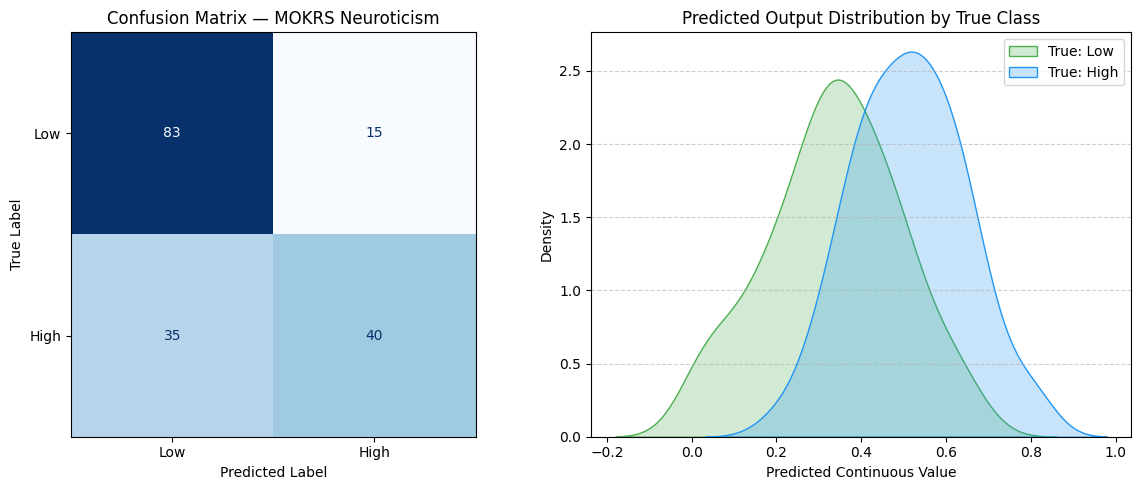

In [ ]:
# Prepare data
y = (agg['NEOFFI_Neuroticism'].values >
     np.median(agg['NEOFFI_Neuroticism'].values)).astype(int)
X_scaled = scaler.fit_transform(agg[features].values)

# Train MOKRS model
mokrs = KernelRidge(alpha=1.0, kernel='rbf')
mokrs.fit(X_scaled, y)

# Predict continuous output, then round to binary class (0/1)
y_pred_cont = mokrs.predict(X_scaled)
y_pred = np.rint(y_pred_cont).astype(int)

# Compute accuracy
acc_neuroticism = round(accuracy_score(y, y_pred), 3)
print(f"✅ Neuroticism Accuracy (MOKRS): {acc_neuroticism}")

# --- Classification Report ---
from sklearn.metrics import classification_report
print("\n📊 Classification Report:")
print(classification_report(y, y_pred, target_names=["Low", "High"]))

# Ensure directory exists
os.makedirs("/mnt/data", exist_ok=True)

# Save model and scaler
with open("/mnt/data/mokrs_neuroticism.pkl", "wb") as f:
    pickle.dump({'model': mokrs, 'scaler': scaler}, f)

print("📁 MOKRS model saved → /mnt/data/mokrs_neuroticism.pkl")

# ===================== ADDITIONAL VISUALIZATION =====================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Confusion Matrix
cm = confusion_matrix(y, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Low", "High"])

plt.figure(figsize=(12,5))

# Plot 1: Confusion Matrix
plt.subplot(1,2,1)
disp.plot(ax=plt.gca(), cmap='Blues', colorbar=False)
plt.title("Confusion Matrix — MOKRS Neuroticism")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

# Plot 2: Smooth Distribution Curve (KDE)
plt.subplot(1,2,2)
sns.kdeplot(y_pred_cont[y == 0], fill=True, color='#4CAF50', label='True: Low')
sns.kdeplot(y_pred_cont[y == 1], fill=True, color='#2196F3', label='True: High')
plt.title("Predicted Output Distribution by True Class")
plt.xlabel("Predicted Continuous Value")
plt.ylabel("Density")
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


In [ ]:
import tensorflow as tf

svm_data = pickle.load(open('/mnt/data/svm_openness.pkl','rb'))
bilstm_model = tf.keras.models.load_model('/mnt/data/bilstm_conscientiousness.h5')
at3net_model = tf.keras.models.load_model('/mnt/data/at3net_extraversion_highacc.h5')
rf_data = pickle.load(open('/mnt/data/rf_agreeableness.pkl','rb'))
mokrs_data = pickle.load(open('/mnt/data/mokrs_neuroticism.pkl','rb'))

def predict_personality(sample_features):
    sample = np.array(sample_features).reshape(1,-1)

    # Openness → SVM
    s_svm = svm_data['scaler'].transform(sample)
    opn = svm_data['model'].predict(s_svm)[0]

    # Conscientiousness → Bi-LSTM
    s_scaled = scaler.transform(sample)
    s_seq = np.repeat(s_scaled[:,np.newaxis,:],3,axis=1)
    cons = np.argmax(bilstm_model.predict(s_seq,verbose=0),axis=1)[0]

    # Extraversion → AT3Net
    s_seq = np.repeat(s_scaled[:,np.newaxis,:],5,axis=1)
    extra = np.argmax(at3net_model.predict(s_seq,verbose=0),axis=1)[0]

    # Agreeableness → RF
    s_rf = rf_data['scaler'].transform(sample)
    agree = rf_data['model'].predict(s_rf)[0]

    # Neuroticism → MOKRS
    s_mokrs = mokrs_data['scaler'].transform(sample)
    neuro = int(round(mokrs_data['model'].predict(s_mokrs)[0]))

    return {
        "Openness": opn,
        "Conscientiousness": cons,
        "Extraversion": extra,
        "Agreeableness": agree,
        "Neuroticism": neuro
    }
print("✅ Unified predictor ready.")


✅ Unified predictor ready.


In [ ]:
sample = agg[features].iloc[0].values
pred = predict_personality(sample)
print("🧠 Predicted Personality Profile:")
for k,v in pred.items():
    print(f"{k:17s}: {'High' if v==1 else 'Low'}")


🧠 Predicted Personality Profile:
Openness         : Low
Conscientiousness: High
Extraversion     : Low
Agreeableness    : Low
Neuroticism      : High


In [ ]:


accuracies = {
    'Trait': ['Openness', 'Conscientiousness', 'Extraversion', 'Agreeableness', 'Neuroticism'],
    'Accuracy': [acc_openness,acc_conscientiousness, acc_extraversion, acc_agreeableness, acc_neuroticism]
}

df_accuracies = pd.DataFrame(accuracies)
print("✅ Collected Accuracy Scores:")
display(df_accuracies)

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.barplot(x='Trait', y='Accuracy', data=df_accuracies, palette='viridis')
plt.title('Accuracy of Models for OCEAN Personality Traits')
plt.xlabel('Personality Trait')
plt.ylabel('Accuracy')
plt.ylim(0, 1.05) # Set y-axis limit from 0 to 1 for accuracy
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()
print("✅ Bar chart displaying model accuracies generated.")

In [ ]:
overall_accuracy = df_accuracies['Accuracy'].mean()
print(f"✅ Overall Model Accuracy: {overall_accuracy:.3f}")